# Local minima and the warm start — Sec. III C

This notebook regenerates, from the data in [`data/`](data/), the local-minimum analysis of Sec. III C for the
irregular graph $G_1$ and the complete graph $K_6$ (Max 3-Cut, six qutrits):

| Output | In the manuscript |
|---|---|
| `figures/G1_l1.pdf`, `figures/G1_l2.pdf` | Fig. 8 a), b) |
| `figures/K6_l1.pdf`, `figures/K6_l2.pdf` | Fig. 9 a), b) |
| tables printed below | the numbers quoted in the text of Sec. III C |

Figure numbers refer to the current version of the manuscript.

**What the data contain.** Each file is one Qudit-ADAPT run. At every iteration $k$, the $k$-parameter ansatz
selected by the algorithm was re-optimized from three starting points:

| Field | Starting point |
|---|---|
| `recycled_energy[k]` | warm start, $\boldsymbol\theta_k=(\boldsymbol\theta_{k-1}^*,0)$ — what Qudit-ADAPT does |
| `cold_energy[k]` | cold restart, $\boldsymbol\theta_k=\boldsymbol 0_k$ |
| `random_runs[k]` | 100 random initializations, $\theta_j\sim\mathcal U(-\pi,\pi)$: initial point `x0` and converged `final_energy` |

The relative error is $\epsilon_{\rm rel}=|E-E_0|/|E_0|$, with $E_0$ = `ground_energy`.

In [1]:
import json
import shutil
import subprocess
from collections import defaultdict
from pathlib import Path

import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt


def latex_with_txfonts():
    """The manuscript figures are rendered with LaTeX and the txfonts package."""
    if shutil.which("latex") is None or shutil.which("kpsewhich") is None:
        return False
    found = subprocess.run(["kpsewhich", "txfonts.sty"], capture_output=True, text=True).stdout
    return bool(found.strip())


USE_TEX = latex_with_txfonts()   # falls back to the STIX fonts, which look very similar

mpl.rcdefaults()
mpl.rcParams.update({
    "font.family": "serif",
    "font.size": 12,
    "axes.labelsize": 14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
})
if USE_TEX:
    mpl.rcParams.update({
        "text.usetex": True,
        "text.latex.preamble": r"\usepackage{amsmath}\usepackage{amssymb}\usepackage{bm}\usepackage{txfonts}",
    })
else:
    mpl.rcParams.update({"mathtext.fontset": "stix", "font.serif": ["STIXGeneral"]})

FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)
print("LaTeX rendering:", USE_TEX)

import matplotlib.image as mpimg
import matplotlib.ticker as mticker
from matplotlib.colors import LogNorm
from matplotlib.offsetbox import AnnotationBbox, OffsetImage

LaTeX rendering: True


In [2]:
DATA = Path("data")
RUNS = {name: json.load(open(DATA / f"{name}.json", encoding="utf-8"))
        for name in ("G1_l1", "G1_l2", "K6_l1", "K6_l2")}
for name, run in RUNS.items():
    print(f"{name}: n={run['n']}, {run['num_edges']} edges, l={run['l']}, {run['num_ansatz_ops']} operators, "
          f"stop: {run['stop_reason']}")

G1_l1: n=6, 10 edges, l=1, 21 operators, stop: gradient_norm_below_epsilon
G1_l2: n=6, 10 edges, l=2, 35 operators, stop: max_iteration_reached
K6_l1: n=6, 15 edges, l=1, 31 operators, stop: gradient_norm_below_epsilon
K6_l2: n=6, 15 edges, l=2, 18 operators, stop: gradient_norm_below_epsilon


In [3]:
def relative_error(energy, run, floor=1e-16):
    e0 = run["ground_energy"]
    return np.clip(np.abs(np.asarray(energy, float) - e0) / abs(e0), floor, None)


def random_cloud(run):
    """(k, relative error) of every converged random initialization."""
    ks, errors = [], []
    for k, runs_k in enumerate(run["random_runs"]):
        for r in runs_k:
            ks.append(k)
            errors.append(r["final_energy"])
    return np.array(ks, float), relative_error(errors, run)


LABEL_WARM = r"Warm start: $\boldsymbol{\theta}_k = (\boldsymbol{\theta}_{k-1}, 0)$"
LABEL_COLD = r"Cold start: $\boldsymbol{\theta}_k = \boldsymbol{0}_k$"
LABEL_RANDOM = r"Random restarts ($100$ per $k$)"


def graph_inset(ax, path, zoom=0.10, xy=(0.155, 0.40)):
    """Draw the graph image inside the axes, with its white background made transparent."""
    img = mpimg.imread(path)
    rgb = img[..., :3].astype(float)
    alpha = np.clip((1.0 - rgb.min(axis=-1)) / 0.07, 0.0, 1.0)
    box = OffsetImage(np.dstack([rgb, alpha]), zoom=zoom)
    ax.add_artist(AnnotationBbox(box, xy, xycoords="axes fraction", frameon=False, zorder=3))


def panel(ax, run, graph_image):
    ks, errors = random_cloud(run)
    jitter = np.random.default_rng(0).uniform(-0.16, 0.16, size=len(ks))
    ax.scatter(ks + jitter, errors, c=errors, cmap="turbo", norm=LogNorm(vmin=errors.min(), vmax=errors.max()),
               marker="_", s=95, linewidths=1.3, alpha=0.55, zorder=2, rasterized=True, label=LABEL_RANDOM)
    warm, cold = relative_error(run["recycled_energy"], run), relative_error(run["cold_energy"], run)
    k = np.arange(len(warm))
    ax.plot(k, cold, color="red", lw=1.8, ls="--", marker="o", ms=7, markevery=2, zorder=4, label=LABEL_COLD)
    ax.plot(k, warm, color="blue", lw=1.8, ls="--", marker="x", ms=8, mew=1.8, zorder=5, label=LABEL_WARM)

    ax.set_yscale("log")
    ax.set_xlabel("Number of variational parameters", fontsize=20)
    ax.set_ylabel(r"$\epsilon_{\mathrm{rel}}$", fontsize=25)
    ax.yaxis.set_major_locator(mticker.LogLocator(base=10))
    ax.yaxis.set_major_formatter(mticker.LogFormatterSciNotation(base=10))
    ax.xaxis.set_major_locator(mticker.MaxNLocator(integer=True))
    ax.tick_params(axis="both", which="major", labelsize=16)
    ax.grid(True, which="both", alpha=0.1)
    ax.set_xlim(-1.0, k[-1] + 1.0)

    # leave a free band at the bottom for the graph and the legend
    everything = np.concatenate([errors, warm, cold])
    low, high = everything.min(), everything.max()
    decades = np.log10(high / low)
    extra = min(max(0.24 / 0.76 * decades, 0.55), 1.30)
    ax.set_ylim(low / 10 ** extra, high * 10 ** (0.06 * decades))

    graph_inset(ax, graph_image)
    handles, labels = ax.get_legend_handles_labels()
    order = [labels.index(x) for x in (LABEL_WARM, LABEL_COLD, LABEL_RANDOM)]
    ax.legend([handles[i] for i in order], [labels[i] for i in order],
              loc="lower left", fontsize=13, frameon=True, framealpha=0.9)

## Figs. 8 and 9

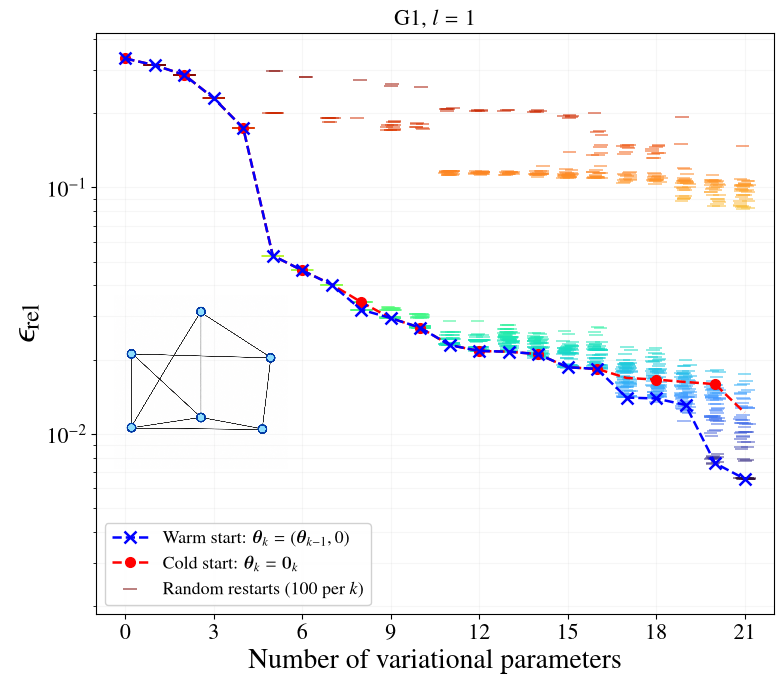

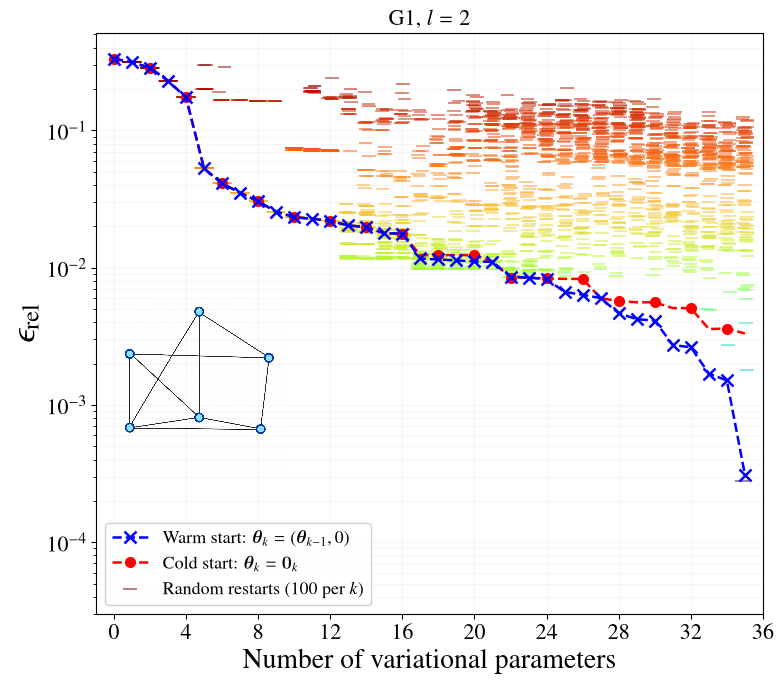

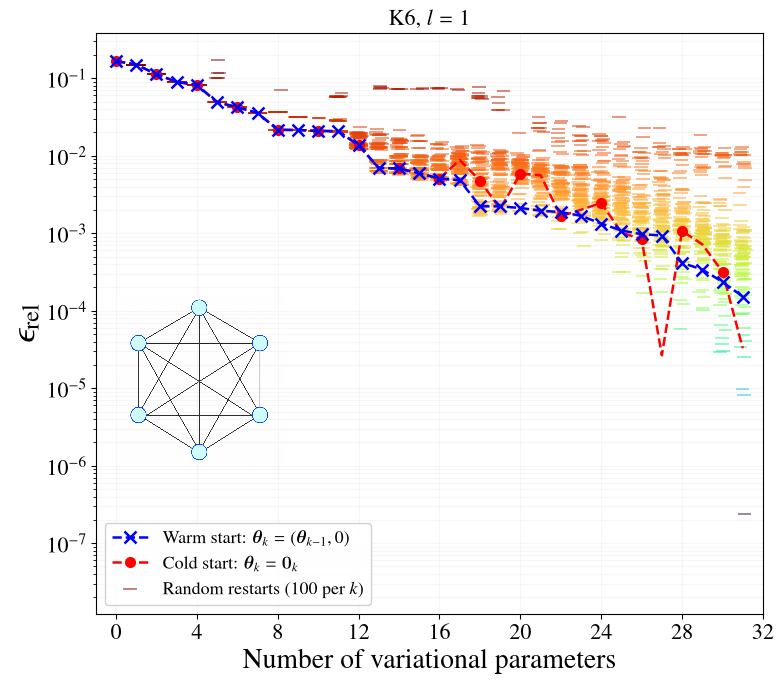

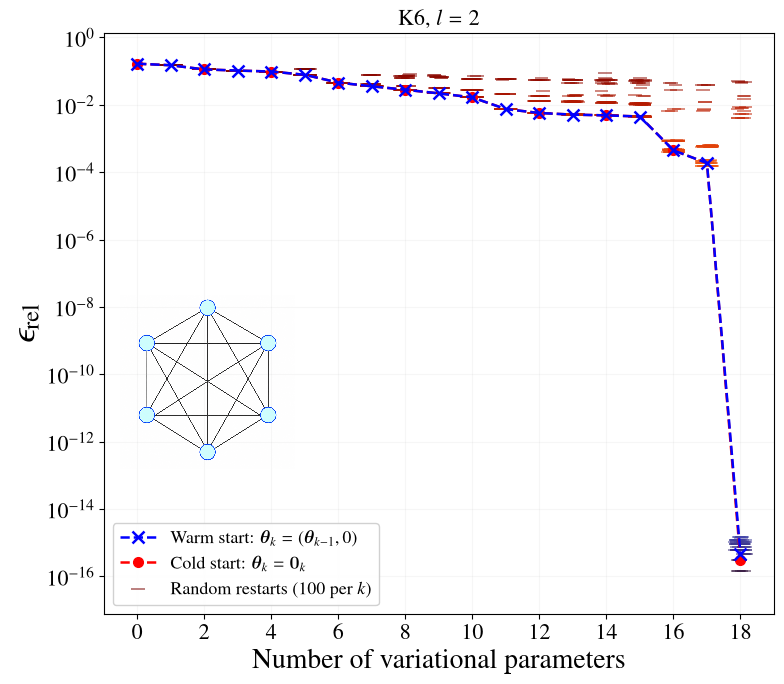

In [4]:
for name, run in RUNS.items():
    fig, ax = plt.subplots(figsize=(8, 7))
    panel(ax, run, Path("graphs") / f"{run['graph']}.png")
    ax.set_title(f"{run['graph']}, $l={run['l']}$", fontsize=16)
    fig.tight_layout()
    ax.set_title("")                  # the manuscript labels the panels from LaTeX
    fig.savefig(FIGURES / f"{name}.pdf")
    ax.set_title(f"{run['graph']}, $l={run['l']}$", fontsize=16)
    plt.show()

## Numbers quoted in Sec. III C

* **distinct minima**: number of different converged energies among the 100 random initializations at the
  final ansatz size (energies rounded to $10^{-8}$);
* **below warm**: random initializations that end at a lower energy than the warm start by more than
  $10^{-10}$ (smaller differences are numerical noise: those runs reach the same minimum);
* **warm ≠ cold from k**: first ansatz size at which the warm and cold relative errors differ by more than 1%;
* **pool**: number of operators in the pool. For $l=2$ the pool lists the $l=1$ operators twice (they appear in
  both $O_1$ and $O_3$); the distinct count is given in parentheses.

In [5]:
print(f"{'run':6} {'k':>3} {'pool':>11} | {'warm':>9} {'cold':>9} | {'random min':>10} {'median':>9} "
      f"{'max':>9} | {'distinct':>8} {'below warm':>10} | {'warm != cold from k':>19}")
for name, run in RUNS.items():
    K = run["num_ansatz_ops"]
    warm, cold = relative_error(run["recycled_energy"], run), relative_error(run["cold_energy"], run)
    final = np.array([r["final_energy"] for r in run["random_runs"][K]])
    rel = relative_error(final, run)
    distinct = len(np.unique(np.round(final, 8)))
    below = int(np.sum(final < run["recycled_energy"][-1] - 1e-10))
    split = np.where(np.abs(warm - cold) / warm > 0.01)[0]
    pool = f"{run['pool_size']} ({len(set(run['pool_labels']))})"
    print(f"{name:6} {K:3d} {pool:>11} | {warm[-1]:9.2e} {cold[-1]:9.2e} | {rel.min():10.2e} {np.median(rel):9.2e} "
          f"{rel.max():9.2e} | {distinct:8d} {below:10d} | {split[0] if len(split) else '-':>19}")

run      k        pool |      warm      cold | random min    median       max | distinct below warm | warm != cold from k
G1_l1   21     46 (46) |  6.56e-03  1.22e-02 |   6.56e-03  1.36e-02  1.47e-01 |       88          0 |                   8
G1_l2   35 1184 (1138) |  3.11e-04  3.31e-03 |   2.79e-04  5.46e-02  1.26e-01 |      100          1 |                  17
K6_l1   31     66 (66) |  1.52e-04  3.29e-05 |   2.41e-07  5.40e-04  1.30e-02 |       99         14 |                  17
K6_l2   18 2724 (2658) |  4.44e-16  2.96e-16 |   1.48e-16  8.88e-16  5.25e-02 |       18          0 |                  18


## Gradient variance at the random initial points

The text compares the variance of $\partial_\theta E$ at the random initial points $\boldsymbol\theta^{(0)}$ with
the ansatz size. To recompute it independently of the rest of the repository, the cells below rebuild the
ansatz from the operator labels with a minimal state-vector simulator. They first check that the simulator
reproduces the stored warm-start energy, and then evaluate the exact gradient (adjoint method) at the stored
initial points `x0`.

Conventions, as in the run files: qutrit basis $(|1\rangle,|0\rangle,|-1\rangle)$, site 1 is the leftmost tensor
factor, each operator label is a product of angular-momentum factors whose Hermitian part is the generator,
and $|\psi(\boldsymbol\theta)\rangle=e^{-i\theta_kA_k}\cdots e^{-i\theta_1A_1}|+_3\rangle^{\otimes n}$.

In [6]:
import ast
from functools import reduce

S2 = np.sqrt(2)
SPIN1 = {"x": np.array([[0, 1, 0], [1, 0, 1], [0, 1, 0]]) / S2,
         "y": np.array([[0, -1j, 0], [1j, 0, -1j], [0, 1j, 0]]) / S2,
         "z": np.diag([1.0, 0.0, -1.0])}


def on_site(matrix, site, n):
    return reduce(np.kron, [matrix if s == site else np.eye(3) for s in range(1, n + 1)])


def generator(label, n):
    product = np.eye(3 ** n, dtype=complex)
    for site, axis in ast.literal_eval(label):
        product = product @ on_site(SPIN1[axis], site, n)
    return (product + product.conj().T) / 2


def max3cut_diagonal(edges, n):
    z = [np.diag(on_site(SPIN1["z"], s, n)).real for s in range(1, n + 1)]
    return sum(z[i - 1] * z[j - 1] - 2 * (z[i - 1] ** 2 + z[j - 1] ** 2) + 3 * z[i - 1] ** 2 * z[j - 1] ** 2
               for i, j in edges)


class Ansatz:
    def __init__(self, run):
        n = run["n"]
        self.h = max3cut_diagonal(run["edges"], n)
        self.psi0 = np.ones(3 ** n, complex) / np.sqrt(3 ** n)
        self.eig = [np.linalg.eigh(generator(label, n)) for label in run["ansatz_op_labels"]]

    def energy_and_gradient(self, theta):
        states = [self.psi0]
        for t, (w, U) in zip(theta, self.eig):
            states.append(U @ (np.exp(-1j * t * w) * (U.conj().T @ states[-1])))
        psi = states[-1]
        energy = np.real(np.vdot(psi, self.h * psi))
        adjoint, grad = self.h * psi, np.zeros(len(theta))
        for k in range(len(theta) - 1, -1, -1):
            w, U = self.eig[k]
            grad[k] = 2 * np.imag(np.vdot(adjoint, U @ (w * (U.conj().T @ states[k + 1]))))
            adjoint = U @ (np.exp(1j * theta[k] * w) * (U.conj().T @ adjoint))
        return energy, grad


for name in ("G1_l1", "G1_l2"):
    run = RUNS[name]
    ansatz = Ansatz(run)
    e, _ = ansatz.energy_and_gradient(np.array(run["params"]))
    print(f"{name}: simulator energy {e:.12f}, stored warm-start energy {run['recycled_energy'][-1]:.12f}")

G1_l1: simulator energy -19.868734967508, stored warm-start energy -19.868734967508


G1_l2: simulator energy -19.993787277080, stored warm-start energy -19.993787277080


In [7]:
for name in ("G1_l1", "G1_l2"):
    run = RUNS[name]
    ansatz = Ansatz(run)
    variance = []
    for k, runs_k in enumerate(run["random_runs"]):
        if k == 0 or not runs_k:
            continue
        grads = np.concatenate([ansatz.energy_and_gradient(np.array(r["x0"]))[1] for r in runs_k])
        variance.append((k, grads.var()))
    ks, var = np.array(variance).T
    peak = int(ks[np.argmax(var)])
    print(f"{name}: Var[dE/dtheta] between {var.min():.2e} and {var.max():.2e} for k = 1..{int(ks[-1])} "
          f"(maximum at k = {peak}; {var[-1]:.2e} at k = {int(ks[-1])})")

G1_l1: Var[dE/dtheta] between 1.60e-01 and 3.87e-01 for k = 1..21 (maximum at k = 5; 1.60e-01 at k = 21)


G1_l2: Var[dE/dtheta] between 4.10e-02 and 3.87e-01 for k = 1..35 (maximum at k = 5; 4.10e-02 at k = 35)
